In [1]:
## . . Import the plotting and libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy import *

## . . For animation
from matplotlib import animation
from IPython.display import HTML, Image

<h1><center>LAB 5 - Solving Parabolic PDEs for Convection-Diffusion</center></h1>



## NAME: $\hspace{0.5in}$    Clara Pugh          $\hspace{2.5in}$      STUDENT NUMBER:$\hspace{0.5in}$ 10914186

The purpose of this lab is to get you thinking about solving 2D parabolic PDEs for convection-diffusion problems.  In the first part, you will validate your code by comparing the generated numerical solution against the known analytic version. You will then generate numerical solutions for two scenarios where no analytic solution exists.



## Part 1 - Validating Against a Known Solution

You are given a 2D rectanglar region of homogeneous material of uniform thermal conductivity $\kappa=6.25\times 10^{-4}$ m$^2$/s with dimensions of $0\le x \le 2$ and $0\le y \le 2$ and are looking to compute the interior temperature profile $T(x,y,t)$. The four sides of the rectangle are held at the following **constant** temperatures:

$$T(x=0,y) = 0 \tag{1a}$$
$$T(x=2,y) = 0 \tag{1b}$$
$$T(x,y=0) = 0 \tag{1c}$$
$$T(x,y=2) = 0 \tag{1d}$$

The initial temperature profile is given by

$$T(x,y,t=0) = f(x,y) = \left\{  
\begin{array}{c}
50\quad {\rm if}\,\, y\,\,\lt 1\\
25\quad {\rm if}\,\, y\,\,= 1\\
0 \quad {\rm if}\,\, y\,\,\gt 1
\end{array}
\right.
$$


Fortunately, you are also given the following theoretical solution to this problem:

$$T_A(x,y,t) = \frac{200}{\pi^2}
\sum_{m=1}^\infty \sum_{n=1}^\infty
\left(
\frac{(1+(-1)^{m+1})\left(1-\cos \frac{n\pi}{2}\right)}{mn}\sin\frac{m\pi x}{2} \sin\frac{n\pi y}{2}\, e^\frac{-\kappa\pi^2(m^2+n^2)t}{4}
\right).
\tag{2}
$$

**Q1-1**: Make subplots of the theoretical temperature $T_A(x,y,t)$ at times $t=0.0$s, $t=5.0$s, $t=20.0$s and $t=50.0$s.  Make sure that you use the same colorbar on each plot.  (I found that using stopping the sum when $m$ and $n$ were between 150-200 was sufficient to represent the solution.)

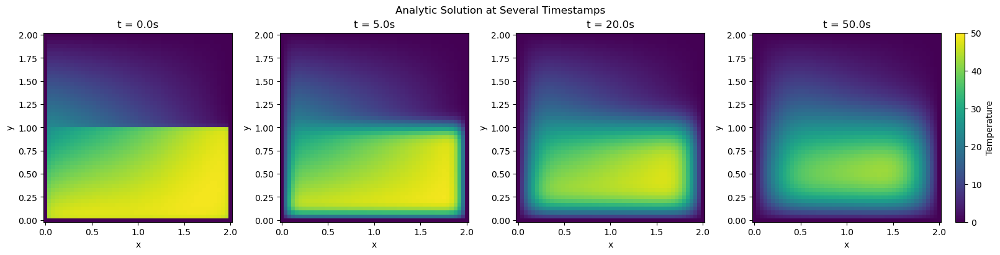

In [2]:
# . . Your answer to Q1-1 goes here

# choose discrete 2D domain:
xmin = 0 # x-axis: 0 ≤ x ≤ 2
xmax = 2 
ymin = 0 # y-axis: 0 ≤ y ≤ 2
ymax = 2
nx = 50 # number of spatial steps for x axis
ny = 50 # number of spatial steps for y axis

# create spatial grid
xx = np.linspace(xmin, xmax, nx)
yy = np.linspace(ymin, ymax, ny)
X, Y = np.meshgrid(xx, yy, indexing='ij')

# set boundary temperatures
TU = 0 # upper
TB = 0 # lower
TL = 0 # left
TR = 0 # right

# create matrix of the right shape to fill in with solution
T = np.zeros((nx,ny))

# go up to m=200 and n=200
m_max = 200
n_max = 200

# set the times to plot
t_0 = 0.0
t_5 = 5.0
t_20 = 20.0
t_50 = 50.0

# set thermal conductivity
k = 0.000625

# define function for analytic solution
def analytic_soln(X,Y,t,T):
    # go through m and n sums
    for m in range(1, m_max):
        for n in range(1, n_max):
            # define each term to multiply inside the sum
            frac_term = (1+((-1)**(m+1))*(1-np.cos(n*np.pi/2)))/(m*n)
            sin_terms = np.sin(m*np.pi*X/2)*np.sin(n*np.pi*Y/2)
            e_term = np.exp(-k * np.pi**2 * (m**2 + n**2) * t /4)
            # multiply and add that to running sum
            delta_T = frac_term * sin_terms * e_term
            T = T + delta_T
    # multiply the coefficient
    T = T*200/(np.pi**2)

    return T

# use function to get T for each timestamp
T_0 = analytic_soln(X,Y,t_0,T)
T_5 = analytic_soln(X,Y,t_5,T)
T_20 = analytic_soln(X,Y,t_20,T)
T_50 = analytic_soln(X,Y,t_50,T)

# plot
fig, ax = plt.subplots(1,4, figsize = (16,4), layout='constrained')

# t = 0
plt.sca(ax[0])
plt.pcolormesh(X, Y, T_0, shading='auto', vmin=0, vmax=50)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f't = {t_0}s')

# t = 5
plt.sca(ax[1])
plt.pcolormesh(X, Y, T_5, shading='auto', vmin=0, vmax=50)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f't = {t_5}s')

# t = 20
plt.sca(ax[2])
plt.pcolormesh(X, Y, T_20, shading='auto', vmin=0, vmax=50)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f't = {t_20}s')

# t = 50
plt.sca(ax[3])
plt.pcolormesh(X, Y, T_50, shading='auto', vmin=0, vmax=50)
plt.colorbar(label='Temperature')
plt.xlabel('x')
plt.ylabel('y')
plt.title(f't = {t_50}s')

plt.suptitle('Analytic Solution at Several Timestamps')
plt.show()

**Q1-2:** Let's start with the grid sampled at $\Delta x = \Delta y = 0.02$m and using a time step of $\Delta t = 0.05$s.  Generate your 2D numerical solution for this problem using the 2D Crank-Nicholson solution approach developed at the end of the  notebook. To illustrate your numerical solution, develop an animation showing: (1) the analytic solution $T_A$, (2) the numerical solution at the current solution step (i.e., $T^n_{i,j}$), and (3) the difference between the analytic and numerical solutions at the current solution step (i.e., $T_A-T^n_{i,j}$). If you are unable to generate an animation, please include illustrative plots to show the solution.

In [3]:
## . . Your answer to Q1-2 goes here

# function to implement Thomas Algorithm solution
def TDMAsolver(a, b, c, d):
    '''
    TDMA solver, a b c d can be NumPy array type or Python list type.
    refer to http://en.wikipedia.org/wiki/Tridiagonal_matrix_algorithm
    input:
        a : left   (i-1) coefficients
        b : center ( i ) coefficients
        c : right  (i+1) coefficients
        d : right hand vector of, e.g., heat distribution values at time t
    output:
        xc: Solution of, e.g., heat distribution vector at time t+∆t

        Note: a,b,c all have the same size. The first element of a and last
        element of b are not used.
    '''
    nf = len(d) # number of equations
    ac, bc, cc, dc = map(np.array, (a, b, c, d)) # copy arrays

    ## . . Forward sweep
    for it in range(1, nf):
        mc = ac[it]/bc[it-1]
        bc[it] = bc[it] - mc*cc[it-1] # . . Overwriting b
        dc[it] = dc[it] - mc*dc[it-1] # . . Overwriting d

    ## . . Backsubstitution sweep
    xc = bc
    xc[-1] = dc[-1]/bc[-1]

    for il in range(nf-2, -1, -1):
        xc[il] = (dc[il]-cc[il]*xc[il+1])/bc[il]

    return xc


# function to set up tridiagonal matrix according to Crank-Nicholson method and solve
def Solve_2D_Convection_Diffusion_homogeneous_Thomas(U,K,vx,vy,dx,dy,dt,LB,RB,BB,TB):
    '''Set up tridiagonal matrix and call Thomas Algorithm
    usage: x = Solve_2D_Convection_Diffusion_homogeneous_Thomas(U,K,vx,vy,dx,dy,dt,LB,RB,BB,TB):
    input:
        U: heat solution at time step n   (nx)
        K : thermal diffusivity
        vx: convection velocity in x-direction
        vy: convection velocity in y-direction
        dx: spatial sampling in x-direction
        dy: spatial sampling in y-direction
        dt: temporal sampling
        LB: Left   boundary condition (Dirchelet)
        RB: Right  boundary condition (Dirchelet)
        BB: Bottom boundary condition (Dirchelet)
        TB: Top    boundary condition (Dirchelet)
    output:
        u: heat solution at time step n+1 (nx,ny)
    depends on:
        TDMAsolver

    written by Jeff Shragge, jshragge@mines.edu, 10/2019
    '''
    ## . . Get dimensions
    nx,ny = np.size(U,0),np.size(U,1)
    U1 = np.zeros((nx,ny))

    ## Enforce boundary condition
    U[0,:] = TB
    U[-1,:] = BB
    U[:,0] = LB
    U[:,-1] = RB

    U1[0,:] = TB
    U1[-1,:] = BB
    U1[:,0] = LB
    U1[:,-1] = RB

    ## . . Define diffusivity and Courant numbers
    AX = K *dt/(dx*dx) ## Diffusivity x: alpha
    AY = K *dt/(dy*dy) ## Diffusivity y: alpha
    CX = vx*dt/ dx     ## Courant x : C
    CY = vy*dt/ dy     ## Courant y : C

    ## . . Set up coefficients in X
    ax =-(CX+2*AX)*np.ones(nx-2)
    bx =  4*(1+AX)*np.ones(nx-2)
    cx = (CX-2*AX)*np.ones(nx-2)

    ## . . Set up coefficients in Y
    ay =-(CY+2*AY)*np.ones(ny-2)
    by =  4*(1+AY)*np.ones(ny-2)
    cy = (CY-2*AY)*np.ones(ny-2)

    ## . . Treat ends
#     ax[0]=cx[nx-1]=ay[0]=cy[ny-1]=0

    ## . . Set up known Solution matrix
    dx = np.zeros((nx-2))
    dy = np.zeros((ny-2))

    ## . . Solve first for update in x direction
    for iy in range(1,ny-1):
        dx[:] =  -(CY-2*AY)*U[1:nx-1,iy+1]+\
                   4*(1-AY)*U[1:nx-1,iy  ]+\
                 +(CY+2*AY)*U[1:nx-1,iy-1]

        dx[0   ]+=+(CY+2*AY)*U[0   ,iy]
        dx[nx-3]+=-(CY-2*AY)*U[nx-1,iy]

        U1[1:nx-1,iy] = TDMAsolver(ax, bx, cx, dx)

    ## . . Solve second for update in yu direction
    for ix in range(1,nx-1):
        dy[:] =  -(CX-2*AX)*U1[ix+1,1:ny-1]+\
                   4*(1-AX)*U1[ix  ,1:ny-1]+\
                 +(CX+2*AX)*U1[ix-1,1:ny-1]

        dy[0   ]+=+(CX+2*AX)*U[ix,0   ]
        dy[ny-3]+=-(CX-2*AX)*U[ix,ny-1]

        U[ix,1:ny-1] = TDMAsolver(ay, by, cy, dy)

    return U

In [4]:
# set up parameters for solution

##   Space and Time Parameters
xmin, xmax = 0.0, 2.0
ymin, ymax = 0.0, 2.0
dx, dy = 0.02, 0.02
dt = 0.05
t_max = 50.0  # Run simulation to 50 seconds

xx = np.linspace(xmin, xmax, int((xmax - xmin) / dx) + 1)
yy = np.linspace(ymin, ymax, int((ymax - ymin) / dy) + 1)
nx, ny = len(xx), len(yy)

X, Y = np.meshgrid(xx, yy, indexing='ij')

##   Initial Condition
U = np.zeros((nx, ny))
U[Y < 1.0] = 50.0
U[np.isclose(Y, 1.0)] = 25.0
U[Y > 1.0] = 0.0

##   PDE Parameters
K = 6.25e-4
vx, vy = 0.0, 0.0
LB = RB = BB = TB = 0.0

##   Time Axis & Array Allocation
times = np.arange(0.0, t_max + dt, dt)
nt = len(times)

# 3D matrix to hold numerical solution at all time steps
p2d = np.zeros((nx, ny, nt))
p2d[:, :, 0] = U.copy()

##   Time Stepping Loop
U_curr = U.copy()
for i in range(1, nt):
    U_curr = Solve_2D_Convection_Diffusion_homogeneous_Thomas(
        U_curr, K, vx, vy, dx, dy, dt, LB, RB, BB, TB
    )
    p2d[:, :, i] = U_curr.copy()

In [5]:
# Helper function to compute analytic solution at arbitrary time t
def get_analytic_T(X, Y, t, m_max=150, n_max=150, k=6.25e-4):
    if t == 0:
        T_analytic = np.zeros_like(X)
        T_analytic[Y < 1.0] = 50.0
        T_analytic[np.isclose(Y, 1.0)] = 25.0
        return T_analytic
    
    # Skip even 'm' values (step by 2) because (1 + (-1)**(m+1)) = 0 when m is even
    # Reshape arrays for broadcasting: m is (m_len, 1, 1, 1), n is (1, n_len, 1, 1)
    m = np.arange(1, m_max, 2).reshape(-1, 1, 1, 1) 
    n = np.arange(1, n_max).reshape(1, -1, 1, 1)
    
    # Since m is always odd, (1 + (-1)**(m+1)) simplifies to exactly 2
    frac_term = (2 * (1 - np.cos(n * np.pi / 2))) / (m * n)
    
    # Compute spatial grids (X and Y are passed in as 2D meshgrids)
    sin_m = np.sin(m * np.pi * X / 2)
    sin_n = np.sin(n * np.pi * Y / 2)
    
    # Compute the time-decay exponential
    e_term = np.exp(-k * np.pi**2 * (m**2 + n**2) * t / 4)
    
    # Multiply everything together and sum across the 'm' (axis 0) and 'n' (axis 1) dimensions
    T_sum = np.sum(frac_term * sin_m * sin_n * e_term, axis=(0, 1))
    
    return T_sum * (200.0 / (np.pi**2))

MovieWriter ffmpeg unavailable; using Pillow instead.


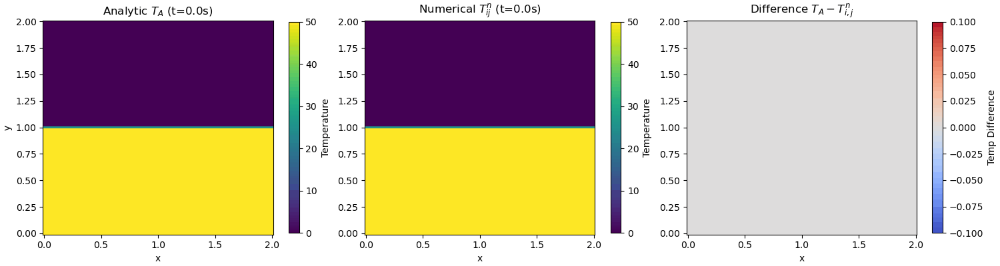

In [6]:
# Setup 3-panel figure
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')

# Skip frames to keep file size reasonable
kskip = 20  # Plot every 1 second (20 * 0.05s)
frame_indices = range(0, nt, kskip)

# Initialize the plots
T_init = p2d[:, :, 0]
T_ana_init = get_analytic_T(X, Y, times[0])
T_diff_init = T_ana_init - T_init

im0 = axes[0].pcolormesh(X, Y, T_ana_init, vmin=0, vmax=50, shading='auto', cmap='viridis')
axes[0].set_title('Analytic $T_A$')
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
fig.colorbar(im0, ax=axes[0], label='Temperature', fraction=0.046, pad=0.04)

im1 = axes[1].pcolormesh(X, Y, T_init, vmin=0, vmax=50, shading='auto', cmap='viridis')
axes[1].set_title('Numerical $T^n_{i,j}$')
axes[1].set_xlabel('x')
fig.colorbar(im1, ax=axes[1], label='Temperature', fraction=0.046, pad=0.04)

im2 = axes[2].pcolormesh(X, Y, T_diff_init, vmin=-0.1, vmax=0.1, shading='auto', cmap='coolwarm')
axes[2].set_title('Difference $T_A - T^n_{i,j}$')
axes[2].set_xlabel('x')
fig.colorbar(im2, ax=axes[2], label='Temp Difference', fraction=0.046, pad=0.04)

def animate(frame_idx):
    t_curr = times[frame_idx]
    T_num = p2d[:, :, frame_idx]
    T_ana = get_analytic_T(X, Y, t_curr)
    T_diff = T_ana - T_num
    
    # 2. Simply update the data arrays for each frame
    # Note: pcolormesh requires flattening the array (ravel) for set_array
    im0.set_array(T_ana.ravel())
    im1.set_array(T_num.ravel())
    im2.set_array(T_diff.ravel())
    
    # Update titles with current time
    axes[0].set_title(f'Analytic $T_A$ (t={t_curr:.1f}s)')
    axes[1].set_title(f'Numerical $T^n_{{ij}}$ (t={t_curr:.1f}s)')
    
    return im0, im1, im2

ani_filename = 'Q1_2_solution.gif'
# Use blit=True for an extra performance boost
anim = animation.FuncAnimation(fig, animate, frames=frame_indices, interval=150, blit=True)
anim.save(ani_filename)
plt.close()
Image(open(ani_filename, 'rb').read())

**Q1-3:** An important question is **how does the choice of time discretization $\Delta t$ affect the accuracy and of the numerical solution**?  Illustrate the difference by redoing question **Q1-2** using 2x the number of time steps at one-half the time sampling (i.e., $\Delta t/2$).  Produce one figure illustrating your numerical solution like you did in **Q1-2**.

In [7]:
## . . Your answer to Q1-3 goes here

##   Space and Time Parameters
dx, dy = 0.02, 0.02
dt = 0.05*2
t_max = 50.0  # Run simulation to 50 seconds

xx = np.linspace(xmin, xmax, int((xmax - xmin) / dx) + 1)
yy = np.linspace(ymin, ymax, int((ymax - ymin) / dy) + 1)
nx, ny = len(xx), len(yy)

X, Y = np.meshgrid(xx, yy, indexing='ij')

##   Initial Condition for Part 1
U = np.zeros((nx, ny))
U[Y < 1.0] = 50.0
U[np.isclose(Y, 1.0)] = 25.0
U[Y > 1.0] = 0.0

##   PDE Parameters
K = 6.25e-4
vx, vy = 0.0, 0.0
LB = RB = BB = TB = 0.0

##   Time Axis & Array Allocation
times = np.arange(0.0, t_max + dt, dt)
nt = len(times)

# 3D matrix to hold numerical solution at all time steps
p2d = np.zeros((nx, ny, nt))
p2d[:, :, 0] = U.copy()

##   Time Stepping Loop
U_curr = U.copy()
for i in range(1, nt):
    U_curr = Solve_2D_Convection_Diffusion_homogeneous_Thomas(
        U_curr, K, vx, vy, dx, dy, dt, LB, RB, BB, TB
    )
    p2d[:, :, i] = U_curr.copy()

MovieWriter ffmpeg unavailable; using Pillow instead.


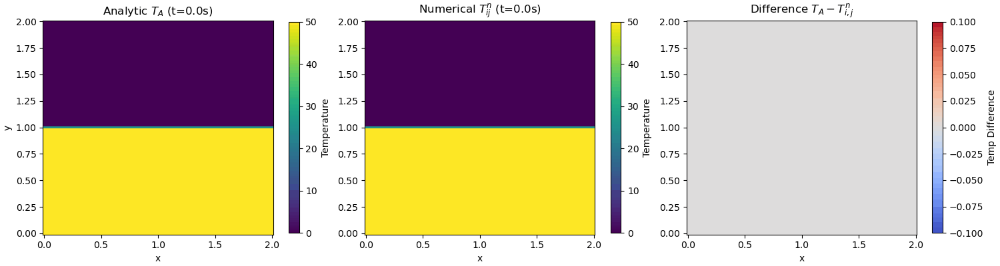

In [8]:
# Setup 3-panel figure
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')

# Skip frames to keep file size reasonable
kskip = 10  # Plot every 1 second (10 * 0.01s)
frame_indices = range(0, nt, kskip)

# Initialize the plots
T_init = p2d[:, :, 0]
T_ana_init = get_analytic_T(X, Y, times[0])
T_diff_init = T_ana_init - T_init

im0 = axes[0].pcolormesh(X, Y, T_ana_init, vmin=0, vmax=50, shading='auto', cmap='viridis')
axes[0].set_title('Analytic $T_A$')
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
fig.colorbar(im0, ax=axes[0], label='Temperature', fraction=0.046, pad=0.04)

im1 = axes[1].pcolormesh(X, Y, T_init, vmin=0, vmax=50, shading='auto', cmap='viridis')
axes[1].set_title('Numerical $T^n_{i,j}$')
axes[1].set_xlabel('x')
fig.colorbar(im1, ax=axes[1], label='Temperature', fraction=0.046, pad=0.04)

im2 = axes[2].pcolormesh(X, Y, T_diff_init, vmin=-0.1, vmax=0.1, shading='auto', cmap='coolwarm')
axes[2].set_title('Difference $T_A - T^n_{i,j}$')
axes[2].set_xlabel('x')
fig.colorbar(im2, ax=axes[2], label='Temp Difference', fraction=0.046, pad=0.04)


ani_filename = 'Q1_3_solution.gif'
# Use blit=True for an extra performance boost
anim = animation.FuncAnimation(fig, animate, frames=frame_indices, interval=150, blit=True)
anim.save(ani_filename)
plt.close()
Image(open(ani_filename, 'rb').read())

**Q1-4:** What happens if you let $\Delta t$ get too large (e.g., $\Delta t=1.0$ s)?

In [9]:
## . . Your answer to Q1-4 goes here

##   Space and Time Parameters
dx, dy = 0.02, 0.02
dt = 1.0
t_max = 50.0  # Run simulation to 50 seconds

xx = np.linspace(xmin, xmax, int((xmax - xmin) / dx) + 1)
yy = np.linspace(ymin, ymax, int((ymax - ymin) / dy) + 1)
nx, ny = len(xx), len(yy)

X, Y = np.meshgrid(xx, yy, indexing='ij')

##   Initial Condition for Part 1
U = np.zeros((nx, ny))
U[Y < 1.0] = 50.0
U[np.isclose(Y, 1.0)] = 25.0
U[Y > 1.0] = 0.0

##   PDE Parameters
K = 6.25e-4
vx, vy = 0.0, 0.0
LB = RB = BB = TB = 0.0

##   Time Axis & Array Allocation
times = np.arange(0.0, t_max + dt, dt)
nt = len(times)

# 3D matrix to hold numerical solution at all time steps
p2d = np.zeros((nx, ny, nt))
p2d[:, :, 0] = U.copy()

##   Time Stepping Loop
U_curr = U.copy()
for i in range(1, nt):
    U_curr = Solve_2D_Convection_Diffusion_homogeneous_Thomas(
        U_curr, K, vx, vy, dx, dy, dt, LB, RB, BB, TB
    )
    p2d[:, :, i] = U_curr.copy()

MovieWriter ffmpeg unavailable; using Pillow instead.


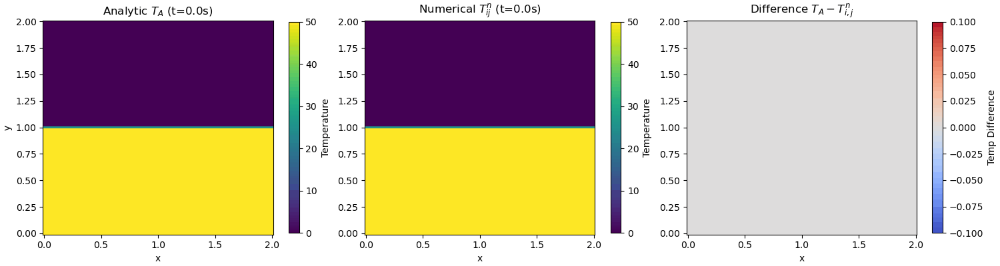

In [10]:
# Setup 3-panel figure
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')

frame_indices = range(0, nt)

# Initialize the plots
T_init = p2d[:, :, 0]
T_ana_init = get_analytic_T(X, Y, times[0])
T_diff_init = T_ana_init - T_init

im0 = axes[0].pcolormesh(X, Y, T_ana_init, vmin=0, vmax=50, shading='auto', cmap='viridis')
axes[0].set_title('Analytic $T_A$')
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
fig.colorbar(im0, ax=axes[0], label='Temperature', fraction=0.046, pad=0.04)

im1 = axes[1].pcolormesh(X, Y, T_init, vmin=0, vmax=50, shading='auto', cmap='viridis')
axes[1].set_title('Numerical $T^n_{i,j}$')
axes[1].set_xlabel('x')
fig.colorbar(im1, ax=axes[1], label='Temperature', fraction=0.046, pad=0.04)

im2 = axes[2].pcolormesh(X, Y, T_diff_init, vmin=-0.1, vmax=0.1, shading='auto', cmap='coolwarm')
axes[2].set_title('Difference $T_A - T^n_{i,j}$')
axes[2].set_xlabel('x')
fig.colorbar(im2, ax=axes[2], label='Temp Difference', fraction=0.046, pad=0.04)


ani_filename = 'Q1_4_solution.gif'
# Use blit=True for an extra performance boost
anim = animation.FuncAnimation(fig, animate, frames=frame_indices, interval=150, blit=True)
anim.save(ani_filename)
plt.close()
Image(open(ani_filename, 'rb').read())

When delta t gets too large, there are a lot of extra errors created, especially at earlier timesteps. This can be seen in the many lines around the border of the initial yellow box area in the difference plot, it has many thin strong red and blue lines corresponding to errors of opposite sign of strong magnitudes.

## Part 2 - Modeling Contaminant Transport

We are now going to come up with a basic modeling of contaminant transport phenomena where a pipe of radius $1$ m is discharging a contaminant with diffusivity of $K=6.25\times10^{-3}$ in water at rate of $C_0$ into a slow-moving river flowing at ${\bf v} = [v_x,v_y]=[0.004,0.004]$ m/s. For the purposes of this simulation, let's say that the river is 100 m wide and we are looking to model 100 m of its length.  The pipe is located at $[x_0,y_0]=[10,10]$ m which leads to the following forcing function

$$F(x,y) = C_0\delta(x-10)\delta(y-10)$$   

Given this setup, the problem we are trying to solve is given by the following **PDE**:

$$\frac{\partial \phi}{\partial t} +
v_x\frac{\partial \phi}{\partial x} +
v_y\frac{\partial \phi}{\partial y}
=  
\frac{\partial }{\partial x}\left(\kappa \frac{\partial \phi}{\partial x}\right)+
\frac{\partial }{\partial y}\left(\kappa \frac{\partial \phi}{\partial y}\right) +F(x,y).$$

for $x\in[0,100]$ m and $y\in[0,100]$ m with the following **Dirichlet boundary conditions** (in meters):

${\rm BOTTOM:} \quad\quad f(x,y=0 ) = 0$

${\rm TOP:}\quad\quad\quad\quad f(x,y=100) = 0$

${\rm LEFT:}\quad\quad\quad\,\, f(x=0,y) =   0$

${\rm RIGHT:}\quad\quad\,\,\,\, f(x=100,y) = 0$

Let's assume that for the **initial condition** that there is zero pollutant concentration such that

$$T(x,y,t=0) = 0$$

**Q2-1:** Let's first start with a grid sampled at $\Delta x = \Delta y = 1$ m and assume that $C_0=1$. Generate a 2D numerical solution for this problem using the 2D Crank-Nicholson solution approach developed at the end of the *05_Parabolic_PDEs.ipynb* notebook for the **first 6 hours of pollution**. Illustrate your numerical solution with an animation.  Choose a $\Delta t$ that provides a reasonably smooth animation. (I chose a $\Delta t$ between 5-60s.)

In [11]:
## . . Your solution to Q2-1 goes here

## Domain and Grid Setup
xmin, xmax = 0, 100
ymin, ymax = 0, 100
dx, dy = 1, 1
dt = 30
t_max = 21600 # 6 hours * 3600 seconds = 21600 seconds

xx = np.linspace(xmin, xmax, int((xmax-xmin)/dx)+1)
yy = np.linspace(ymin, ymax, int((ymax-ymin)/dy)+1)
nx, ny = len(xx), len(yy)
X, Y = np.meshgrid(xx, yy, indexing='ij')

## PDE Parameters
K = 6.25e-3
vx, vy = 0.004, 0.004
LB = RB = BB = TB = 0
C0 = 1.0

## Identify the grid index for the source at x=10, y=10
# Since dx=dy=1 and domain starts at 0, the indices are exactly 10 and 10.
ix_src, iy_src = 10, 10

## Initial Condition U(x, y, t=0)
U = np.zeros((nx, ny))

## Time Stepping Setup
times = np.arange(0.0, t_max + dt, dt)
nt = len(times)

# 3D array to store solutions over time
p2d_part2 = np.zeros((nx, ny, nt))
p2d_part2[:, :, 0] = U.copy()

## Time-Stepping Loop
U_curr = U.copy()

for i in range(1, nt):
    # 1. Apply the forcing function (contaminant source)
    # The PDE states d(phi)/dt = ... + F(x,y). In a discrete time step, we add C0 * dt.
    U_curr[ix_src, iy_src] += C0 * dt
    
    # 2. Compute the convection-diffusion step
    U_curr = Solve_2D_Convection_Diffusion_homogeneous_Thomas(
        U_curr, K, vx, vy, dx, dy, dt, LB, RB, BB, TB
    )
    
    # 3. Save to array
    p2d_part2[:, :, i] = U_curr.copy()

MovieWriter ffmpeg unavailable; using Pillow instead.


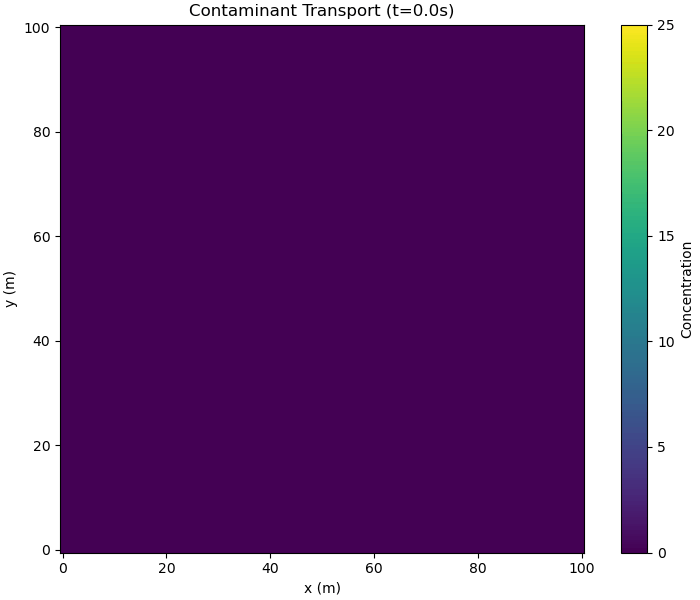

In [12]:
## Setup 1-panel figure for animation
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')

# Skip frames to keep file size reasonable (e.g., render every 20th frame)
kskip = 20 
frame_indices = range(0, nt, kskip)

# Initialize the plot
T_init = p2d_part2[:, :, 0]
im = ax.pcolormesh(X, Y, T_init, shading='auto', cmap='viridis', vmin=0, vmax=25)
fig.colorbar(im, ax=ax, label='Concentration')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')

# Redefine the animate function specifically to use p2d_part2
def animate_part2(frame_idx):
    t_curr = times[frame_idx]
    T_num = p2d_part2[:, :, frame_idx]
    
    im.set_array(T_num.ravel())
    ax.set_title(f'Contaminant Transport (t={t_curr:.1f}s)')
    return im,

ani_filename = 'Q2_solution.gif'
anim = animation.FuncAnimation(fig, animate_part2, frames=frame_indices, interval=100, blit=True)
anim.save(ani_filename)
plt.close()

Image(open(ani_filename, 'rb').read())

## Part 3 - Incorporating a more complex stream velocity

You now want to model a more realistic stream velocity since having a constant stream throughout is not realistic. Your hydrologist friend suggests using the following stream function:

$${\bf v} = [v_x,v_y] = [(1+5e^{-(y-50)^2/400})/250,1/250]$$

**Q3-1:** Adapt your solution from Part 2 to incorporate this stream velocity function.  Note that this will require you to incorporate a spatially variable $v_x$ and $v_y$ function in your previous solver. The other components of your coding solution should largely be the same.

In [13]:
## . . Your answer to Q3-1 goes here

## Domain and Grid Setup
xmin, xmax = 0, 100
ymin, ymax = 0, 100
dx, dy = 1, 1
dt = 30
t_max = 21600 # 6 hours * 3600 seconds = 21600 seconds

xx = np.linspace(xmin, xmax, int((xmax-xmin)/dx)+1)
yy = np.linspace(ymin, ymax, int((ymax-ymin)/dy)+1)
nx, ny = len(xx), len(yy)
X, Y = np.meshgrid(xx, yy, indexing='ij')

## PDE Parameters
K = 6.25e-3
LB = RB = BB = TB = 0
C0 = 1.0  # Contaminant discharge rate
# update vx and vy to spatially variable 
vx = (1 + 5 * np.exp(-((Y - 50)**2) / 400)) / 250
vy = np.ones_like(Y) / 250

## Identify the grid index for the source at x=10, y=10
# Since dx=dy=1 and domain starts at 0, the indices are exactly 10 and 10.
ix_src, iy_src = 10, 10

## Initial Condition U(x, y, t=0)
U = np.zeros((nx, ny))

## Time Stepping Setup
times = np.arange(0.0, t_max + dt, dt)
nt = len(times)

In [14]:
# define new function to solve with spatially varying velocity

def Solve_2D_Convection_Diffusion_variable_Thomas(U, K, vx, vy, dx, dy, dt, LB, RB, BB, TB):
    ## Get dimensions
    nx, ny = np.size(U, 0), np.size(U, 1)
    U1 = np.zeros((nx, ny))
    
    ## Enforce boundary condition
    U[0, :] = TB
    U[-1, :] = BB
    U[:, 0] = LB
    U[:, -1] = RB
    
    U1[0, :] = TB
    U1[-1, :] = BB
    U1[:, 0] = LB
    U1[:, -1] = RB
    
    ## Define diffusivity
    AX = K * dt / (dx * dx)
    AY = K * dt / (dy * dy)
    
    ## Courant numbers (now 2D arrays instead of scalars)
    CX = vx * dt / dx
    CY = vy * dt / dy
    
    ## Set up known Solution matrix
    dx_arr = np.zeros((nx - 2))
    dy_arr = np.zeros((ny - 2))
    
    ## Solve first for update in x direction
    for iy in range(1, ny - 1):
        # Extract 1D slice for current row
        CX_iy = CX[1:nx-1, iy]
        CY_iy = CY[1:nx-1, iy]
        
        # Set up coefficients in X for this specific row
        ax = -(CX_iy + 2 * AX) 
        bx = 4 * (1 + AX) * np.ones(nx - 2)
        cx = (CX_iy - 2 * AX) 
        
        dx_arr[:] = -(CY_iy - 2 * AY) * U[1:nx-1, iy + 1] + \
                    4 * (1 - AY) * U[1:nx-1, iy] + \
                    (CY_iy + 2 * AY) * U[1:nx-1, iy - 1]
        
        dx_arr[0] += +(CY[0, iy] + 2 * AY) * U[0, iy]
        dx_arr[nx - 3] += -(CY[nx-1, iy] - 2 * AY) * U[nx - 1, iy]
        
        U1[1:nx-1, iy] = TDMAsolver(ax, bx, cx, dx_arr)
        
    ## Solve second for update in y direction
    for ix in range(1, nx - 1):
        # Extract 1D slice for current column
        CX_ix = CX[ix, 1:ny-1]
        CY_ix = CY[ix, 1:ny-1]
        
        # Set up coefficients in Y for this specific column
        ay = -(CY_ix + 2 * AY) 
        by = 4 * (1 + AY) * np.ones(ny - 2)
        cy = (CY_ix - 2 * AY) 
        
        dy_arr[:] = -(CX_ix - 2 * AX) * U1[ix + 1, 1:ny-1] + \
                    4 * (1 - AX) * U1[ix, 1:ny-1] + \
                    (CX_ix + 2 * AX) * U1[ix - 1, 1:ny-1]
                    
        dy_arr[0] += +(CX[ix, 0] + 2 * AX) * U[ix, 0]
        dy_arr[ny - 3] += -(CX[ix, ny-1] - 2 * AX) * U[ix, ny - 1]
        
        U[ix, 1:ny-1] = TDMAsolver(ay, by, cy, dy_arr)
        
    return U

In [15]:
# 3D array to store solutions over time
p2d_part2 = np.zeros((nx, ny, nt))
p2d_part2[:, :, 0] = U.copy()

## Time-Stepping Loop
U_curr = U.copy()

for i in range(1, nt):
    # 1. Apply the forcing function (contaminant source)
    # The PDE states d(phi)/dt = ... + F(x,y). In a discrete time step, we add C0 * dt.
    U_curr[ix_src, iy_src] += C0 * dt
    
    # 2. Compute the convection-diffusion step
    U_curr = Solve_2D_Convection_Diffusion_variable_Thomas(
        U_curr, K, vx, vy, dx, dy, dt, LB, RB, BB, TB
    )
    
    # 3. Save to array
    p2d_part2[:, :, i] = U_curr.copy()

MovieWriter ffmpeg unavailable; using Pillow instead.


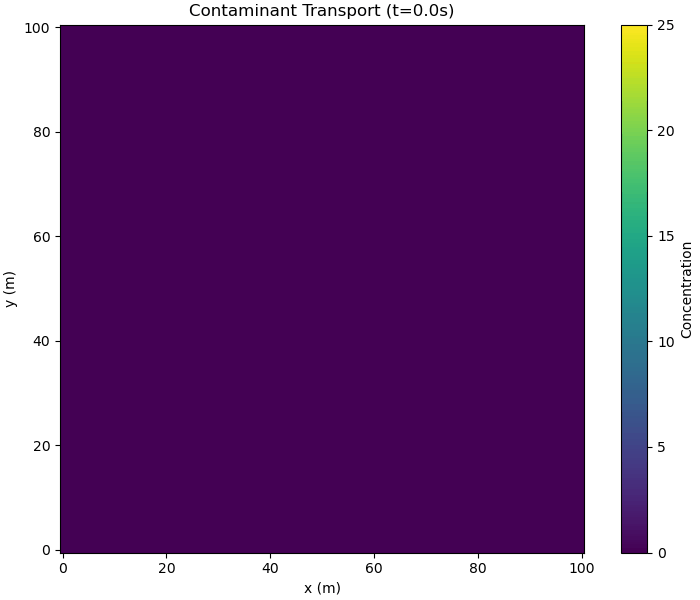

In [16]:
## Setup 1-panel figure for animation
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')

# Skip frames to keep file size reasonable (e.g., render every 20th frame)
kskip = 20 
frame_indices = range(0, nt, kskip)

# Initialize the plot
T_init = p2d_part2[:, :, 0]
# Use a vmax that captures the eventual peak concentration
im = ax.pcolormesh(X, Y, T_init, shading='auto', cmap='viridis', vmin=0, vmax=25)
fig.colorbar(im, ax=ax, label='Concentration')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')

# Redefine the animate function specifically to use p2d_part2
def animate_part2(frame_idx):
    t_curr = times[frame_idx]
    T_num = p2d_part2[:, :, frame_idx]
    
    im.set_array(T_num.ravel())
    ax.set_title(f'Contaminant Transport (t={t_curr:.1f}s)')
    return im,

ani_filename = 'Q2_solution.gif'
anim = animation.FuncAnimation(fig, animate_part2, frames=frame_indices, interval=100, blit=True)
anim.save(ani_filename)
plt.close()

Image(open(ani_filename, 'rb').read())

# Part 4 (GPGN536 only) - Convert Part 3 code into C, verify the results using Python and compare the computational performance.

In [17]:
## . . Your answer to Q4 goes here

# AI Disclosure

Please write in 3-5 lines about:

* Which tools you used​

* What you asked them for​

* What you did with the output​

* If you used none, say so​

I used Gemini to help with debugging and to help figure out how the animation code works. I had it explain how the code works so that I was then able to apply that knowledge in my code.